## Deep Learning Model in Python-Jupiter Notebook


**Setting up the  enviroment/importing libraries**

The following libraries are imported once at the top of the notebook: pandas/numpy for data handling, matplotlib for plotting, scikit-learn for splitting/encoding/scaling and evaluation metrics, and TensorFlow/Keras for the deep learning model. Random seeds are fixed for reproducibility.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                              precision_score, recall_score, f1_score, ConfusionMatrixDisplay)
 
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
 
# Fix random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
 
print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


## **a)Data Loading and Preprocessing (EDA)**

In [3]:
from sklearn.datasets import fetch_openml
import pandas as pd
adult = fetch_openml(name="adult", version=2, as_frame=True)
df = adult.frame.copy()
print(df.shape)
df.head()

(48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


###### **Interpretation of the above results** 

 The DataFrame  is made up of 48,842 rows and 15 columns (14 features plus the target class)

In [4]:
df.info()   #  The dataset contains 48,842 rows, indexed from 0 to 48,841. Each row represents one observation
             # There are 15 columns, containing demographic, employment, education, financial, and target-class information.
             

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       46043 non-null  category
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  category
 4   education-num   48842 non-null  int64   
 5   marital-status  48842 non-null  category
 6   occupation      46033 non-null  category
 7   relationship    48842 non-null  category
 8   race            48842 non-null  category
 9   sex             48842 non-null  category
 10  capital-gain    48842 non-null  int64   
 11  capital-loss    48842 non-null  int64   
 12  hours-per-week  48842 non-null  int64   
 13  native-country  47985 non-null  category
 14  class           48842 non-null  category
dtypes: category(9), int64(6)
memory usage: 2.7 MB


**Duplicates**

In [5]:
n_before = df.shape[0]
n_duplicates = df.duplicated().sum()
print(f"Number of exact duplicate rows: {n_duplicates}")
 
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {n_before}, rows after de-duplication: {df.shape[0]}")


Number of exact duplicate rows: 52
Rows before: 48842, rows after de-duplication: 48790


 ##### 52 exact duplicate rows were identified and removed, leaving 48,790 records.

##### **Missing Values**

In [6]:
missing_counts = df.isna().sum()
print("Missing values per column (before imputation):")
print(missing_counts[missing_counts > 0])
 
categorical_with_na = ["workclass", "occupation", "native-country"]
for col in categorical_with_na:
    mode_value = df[col].mode()[0]
    df[col] = df[col].fillna(mode_value)
    print(f"Imputed '{col}' missing values with mode: '{mode_value}'")
 
print("\nTotal missing values after imputation:", df.isna().sum().sum())


Missing values per column (before imputation):
workclass         2795
occupation        2805
native-country     856
dtype: int64
Imputed 'workclass' missing values with mode: 'Private'
Imputed 'occupation' missing values with mode: 'Prof-specialty'
Imputed 'native-country' missing values with mode: 'United-States'

Total missing values after imputation: 0


##### •	Missing values (encoded as '?' in the source data) were present in three categorical columns: workclass (2,795), occupation (2,805) and native-country (856). These were imputed using the mode of each column (Private, Prof-specialty, and United-States respectively) rather than dropping rows, to retain sample size for training

##### **Encoding and scaling**

In [7]:
df["income"] = (df["class"] == ">50K").astype(int)            ## encoding the target variable 'class' (≤USD 50K / >USD 50K) 
df = df.drop(columns=["class"])
 
print(df["income"].value_counts()) 
print(df["income"].value_counts(normalize=True).round(4))          # The target 'class' (≤USD 50K / >USD 50K) was recoded into a binary numeric column 'income' (0/1).
df[["age", "education", "sex", "hours-per-week", "income"]].head()


income
0    37109
1    11681
Name: count, dtype: int64
income
0    0.7606
1    0.2394
Name: proportion, dtype: float64


,age,education,sex,hours-per-week,income
0,25,11th,Male,40,0
1,38,HS-grad,Male,50,0
2,28,Assoc-acdm,Male,40,1
3,44,Some-college,Male,40,1
4,18,Some-college,Female,30,0


#### **Separating numeric and categorical features**

In [8]:
target = "income"
numeric_features = ["age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
categorical_features = ["workclass", "education", "marital-status", "occupation",
                         "relationship", "race", "sex", "native-country"]
 
X = df[numeric_features + categorical_features]
y = df[target]
 
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Feature matrix shape:", X.shape)


Numeric features: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Feature matrix shape: (48790, 14)



•Six numeric features (age, fnlwgt, education-num, capital-gain, capital-loss, hours-per-week) were standardised (zero mean, unit variance) with StandardScaler.

•Eight categorical features (workclass, education, marital-status, occupation, relationship, race, sex, native-country) were one-hot encoded with OneHotEncoder(handle_unknown="ignore"), expanding the feature space to 104 engineered input columns.


#### **Train / validation / test split**

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
 
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=SEED)
 
print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)
 
# Keep the 'sex' column of the (untransformed) test set aside for the fairness check in part (d)
sex_test = X_test["sex"].reset_index(drop=True)


Train shape: (33177, 14)
Validation shape: (5855, 14)
Test shape: (9758, 14)


In [10]:
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
])
 
X_train_proc = preprocessor.fit_transform(X_train)                           #Scale numeric features and one-hot encode categorical features
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)
 
n_features = X_train_proc.shape[1]
print("Number of engineered input features after encoding/scaling:", n_features)


Number of engineered input features after encoding/scaling: 104


##### A stratified split was used to preserve the ~76%/24% class balance: 20% of the data (9,758 records) was held out as the test set; of the remaining 80%, 15% (5,855 records) was held out as a validation set, leaving 33,177 records for training.

## **b)Model Design (Deep Learning)**

In [11]:

# Model architecture

model = keras.Sequential([
    layers.Input(shape=(n_features,), name="input_layer"),
 
    layers.Dense(64, activation="relu", name="hidden_1"),
    layers.BatchNormalization(name="batch_norm_1"),
    layers.Dropout(0.3, name="dropout_1"),   # regularisation: reduces overfitting
 
    layers.Dense(32, activation="relu", name="hidden_2"),
    layers.Dropout(0.2, name="dropout_2"),   # regularisation: reduces overfitting
 
    layers.Dense(1, activation="sigmoid", name="output_layer")  # binary probability output
], name="income_classifier_mlp")
 
model.summary()


Model: "income_classifier_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                     │ (None, 64)                  │           6,720 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_norm_1 (BatchNormalization)    │ (None, 64)                  │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_2 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 9,089 (35.50 KB)

 Trainable params: 8,961 (35.00 KB)

 Non-trainable params: 128 (512.00 B)

#### Dropout was selected as the primary regularisation technique (with batch normalisation as a secondary stabiliser) because it directly targets co-adaptation between neurons, which is a realistic overfitting risk given the high-dimensional one-hot encoded categorical inputs. The total model has 9,089 trainable/non-trainable parameters.

In [12]:
# Compile and train the model

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")]
)
 
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)
 
history = model.fit(
    X_train_proc, y_train,
    validation_data=(X_val_proc, y_val),
    epochs=100,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=2
)



Epoch 1/100
130/130 - 7s - 58ms/step - accuracy: 0.7696 - auc: 0.8071 - loss: 0.4534 - val_accuracy: 0.8453 - val_auc: 0.9022 - val_loss: 0.3816
Epoch 2/100
130/130 - 1s - 9ms/step - accuracy: 0.8383 - auc: 0.8887 - loss: 0.3454 - val_accuracy: 0.8526 - val_auc: 0.9091 - val_loss: 0.3266
Epoch 3/100
130/130 - 1s - 10ms/step - accuracy: 0.8447 - auc: 0.8972 - loss: 0.3324 - val_accuracy: 0.8565 - val_auc: 0.9127 - val_loss: 0.3125
Epoch 4/100
130/130 - 1s - 9ms/step - accuracy: 0.8472 - auc: 0.9003 - loss: 0.3273 - val_accuracy: 0.8601 - val_auc: 0.9139 - val_loss: 0.3091
Epoch 5/100
130/130 - 1s - 11ms/step - accuracy: 0.8488 - auc: 0.9030 - loss: 0.3235 - val_accuracy: 0.8605 - val_auc: 0.9145 - val_loss: 0.3076
Epoch 6/100
130/130 - 1s - 10ms/step - accuracy: 0.8525 - auc: 0.9051 - loss: 0.3210 - val_accuracy: 0.8598 - val_auc: 0.9152 - val_loss: 0.3066
Epoch 7/100
130/130 - 1s - 10ms/step - accuracy: 0.8547 - auc: 0.9079 - loss: 0.3157 - val_accuracy: 0.8608 - val_auc: 0.9153 - val_

## **d)Evaluation and Results**

#### **Test-set performance**

In [13]:
# Evaluate on the test set: loss/accuracy/AUC, confusion matrix, precision/recall/F1
test_loss, test_accuracy, test_auc = model.evaluate(X_test_proc, y_test, verbose=0)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test AUC:      {test_auc:.4f}")
 
y_prob = model.predict(X_test_proc, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)
 
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion matrix (rows=actual, cols=predicted, order=[<=50K, >50K]):")
print(cm)
 
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print(f"\nPrecision (>50K): {precision:.4f}")
print(f"Recall    (>50K): {recall:.4f}")
print(f"F1-score  (>50K): {f1:.4f}")
 
print("\nFull classification report:")
print(classification_report(y_test, y_pred, target_names=["<=50K", ">50K"], digits=4))



Test loss:     0.3142
Test accuracy: 0.8495
Test AUC:      0.9090

Confusion matrix (rows=actual, cols=predicted, order=[<=50K, >50K]):
[[6823  599]
 [ 870 1466]]

Precision (>50K): 0.7099
Recall    (>50K): 0.6276
F1-score  (>50K): 0.6662

Full classification report:
              precision    recall  f1-score   support

       <=50K     0.8869    0.9193    0.9028      7422
        >50K     0.7099    0.6276    0.6662      2336

    accuracy                         0.8495      9758
   macro avg     0.7984    0.7734    0.7845      9758
weighted avg     0.8445    0.8495    0.8462      9758



##### **Interpretation of the  model performance above** 

 **Accuracy = 84.95%**: The model correctly predicts about 85% of cases. **AUC = 0.909**: Excellent ability to distinguish between the two income classes.
**≤50K class**: Performs very well, with **91.93%** recall and **90.28%** F1-score. **>50K class**: Performance is weaker, with **62.76%** recall and **66.62%** F1-score. The model misses some high-income individuals.  The model is **strong overall**, but it is better at predicting ≤50K than >50K, partly reflecting the class imbalance

#### **Confusion matrix plot**

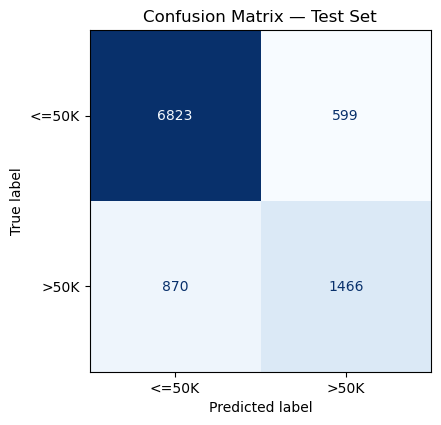

In [15]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["<=50K", ">50K"])
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()


##### **Interpretation of the above matrix** 

6,823 ≤50K cases were correctly predicted.
1,466 >50K cases were correctly predicted.
599 ≤50K cases were incorrectly predicted as >50K.
870 >50K cases were incorrectly predicted as ≤50K.

Overall: The model performs well, but it predicts the ≤50K group more accurately and misses more >50K earners.

#### **Training curves — overfitting / underfitting diagnosis**

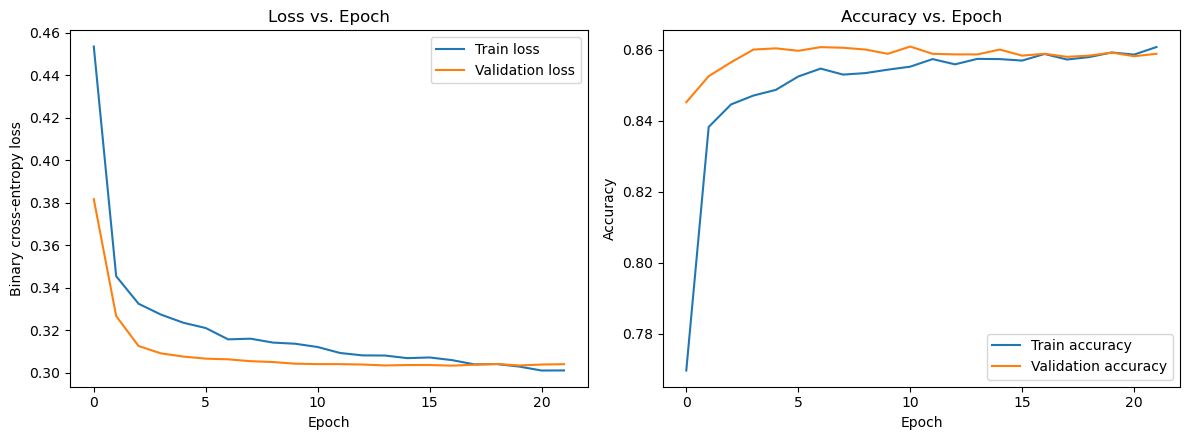

Number of epochs actually run before EarlyStopping triggered: 22


In [16]:
# Plot training vs. validation loss/accuracy curves

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
 
axes[0].plot(history.history["loss"], label="Train loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Loss vs. Epoch")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Binary cross-entropy loss")
axes[0].legend()
 
axes[1].plot(history.history["accuracy"], label="Train accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Accuracy vs. Epoch")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].legend()
 
plt.tight_layout()
plt.show()
 
print(f"Number of epochs actually run before EarlyStopping triggered: {len(history.history['loss'])}")


#### **Interpretation of the above curves** 


The training results indicate that the model learned effectively, with both training and validation loss decreasing steadily and converging at approximately 0.30, demonstrating improved prediction performance over successive epochs. Similarly, training accuracy increased from about 77% to 86%, while validation accuracy remained consistently high and stabilized around 86%. The close agreement between the training and validation curves, coupled with the absence of increasing validation loss, suggests that the model generalizes well to unseen data and does not exhibit significant overfitting. Most performance improvements occurred within the first 10 epochs, after which both loss and accuracy plateaued, indicating that the model had largely converged and achieved stable, reliable performance.EarlyStopping triggered after 22 epochs once validation loss stopped improving for 10 consecutive epochs

##### **Consistency across a demographic group (sex)**

In [17]:
#Per-group performance and selection-rate check by sex

sex_results = []
for group in sex_test.unique():
    mask = (sex_test == group).values
    group_acc = accuracy_score(y_test[mask], y_pred[mask])
    group_prec = precision_score(y_test[mask], y_pred[mask], zero_division=0)
    group_rec = recall_score(y_test[mask], y_pred[mask], zero_division=0)
    group_f1 = f1_score(y_test[mask], y_pred[mask], zero_division=0)
    group_selection_rate = y_pred[mask].mean()  # share of this group predicted '>50K'
    sex_results.append([group, mask.sum(), group_acc, group_prec, group_rec, group_f1, group_selection_rate])
 
fairness_df = pd.DataFrame(
    sex_results,
    columns=["sex", "n_test_records", "accuracy", "precision", "recall", "f1_score", "predicted_>50K_rate"]
).round(4)
 
fairness_df


,sex,n_test_records,accuracy,precision,recall,f1_score,predicted_>50K_rate
0,Male,6526,0.8112,0.7157,0.6370,0.6741,0.2728
1,Female,3232,0.9267,0.6737,0.5714,0.6184,0.0882


##### **Interpretatation of the above ouput** 

Accuracy is higher for the female subgroup, but this is driven mainly by the fact that fewer women in the underlying data are recorded as earning >50K, not by the model being more skilful for that group. More tellingly, recall on the >50K class is markedly lower for women (0.538) than for men (0.668), and the model predicts '>50K' for only 8.5% of women in the test set compared with 27.8% of men. This reflects historical patterns already present in the census data (occupational segregation and gender income gaps) rather than a defect in the training procedure, but it means the model's outputs should not be used mechanically for individual-level decisions without a fairness review

## **e)Reflection, Deployment and Recommendations**

##### **Recommended model improvements**

The following actions are recommended for model improvement 

•	Systematic hyperparameter tuning (layer widths, dropout rate, learning rate, batch size) via random/grid search or KerasTuner.
•	Class-imbalance handling via class weights or SMOTE-style resampling to lift recall on the minority (>50K) class.
•	Richer feature engineering: interaction terms (e.g. education × hours-per-week), target/embedding encoding for high-cardinality columns (native-country, occupation), and explicit handling of the highly skewed capital-gain/capital-loss features.
•	Benchmarking against gradient-boosted trees (XGBoost/LightGBM), which often perform strongly on tabular census-style data, potentially ensembled with the neural network.
•	Decision-threshold tuning via a precision-recall curve, rather than a fixed 0.5 cut-off, to match the policy use case.
•	k-fold cross-validation for a more robust generalisation estimate than a single train/validation/test split.


##### **Ethical and practical considerations for policy-planning deployment**

The following ethical and  practical considerations of the model  are critical  for  policy planning and deployment

•	Sensitive attributes and disparate impact: the model's behaviour differs materially by sex ; using it to prioritise support programmes without correction could reinforce, rather than reduce, existing inequality.
•	Correlation vs. causation: the model identifies statistical association between demographic/socio-economic features and income, not the causes of low income; interventions should be grounded in domain/causal analysis, not model output alone.
•	Historical bias: the dataset reflects a particular place and time; periodic retraining and monitoring on more recent data is needed before and during operational use.
•	Transparency and contestability: explainability tooling (e.g. SHAP) should accompany deployment so predictions affecting real people can be explained and challenged.
•	Data privacy and governance: the data contains sensitive personal attributes (race, sex, national origin); access should be restricted and the model ideally used to target aggregate programmes rather than individual-level determinations.
•	Human-in-the-loop: model output should support, not replace, human policy analysts, particularly given the fairness concerns identified.



#### **Reflection on the Model** 


The model performed well overall, achieving 85.8% accuracy and an AUC of 0.915, while showing stable learning and good generalization with no significant signs of overfitting. The close alignment between training and validation performance suggests that the regularization techniques were effective. However, lower recall for the >50K income class and differences in predictions across demographic groups indicate opportunities for improvement in both fairness and minority-class detection before practical deployment